# Physics 2A: Conservation Laws

In [1]:
import torch
import numpy as np
from xkan import KANNetwork, fit, CompositeLoss
from xkan.losses import FunctionalTerm
from xkan.utils import batch_jacobian, create_dataset_from_data

model = KANNetwork([2, 1], seed=42)
torch.manual_seed(42)  # pykan 0.2's constructor seeded torch's global generator with the model's seed; KANNetwork does not

# the model learns the Hamiltonian H = 1/2 * (x**2 + p**2)
x = torch.rand(1000,2) * 2 - 1
flow = torch.cat([x[:,[1]], -x[:,[0]]], dim=1)

def pred_fn(model, x):
    grad = batch_jacobian(model, x, create_graph=True)
    grad_normalized = grad/torch.linalg.norm(grad, dim=1, keepdim=True)
    return grad_normalized

loss_fn = lambda grad_normalized, flow: torch.mean(torch.sum(flow * grad_normalized, dim=1)**2)

train, test = create_dataset_from_data(x, flow)
# the loss is a function of the model's gradient (pred_fn), not of its output: a FunctionalTerm (outputs, batch, model)
loss = CompositeLoss({"y": FunctionalTerm(lambda outputs, batch, model: loss_fn(pred_fn(model, batch["x"]), batch["y"]))})
history = fit(model, train, test, steps=20, loss=loss)
print('train loss (sqrt)', np.sqrt(history['train/y'][-1]), 'test loss (sqrt)', np.sqrt(history['val/y'][-1]))

train loss (sqrt) 0.00012928707737640976 test loss (sqrt) 0.00011550307500863267


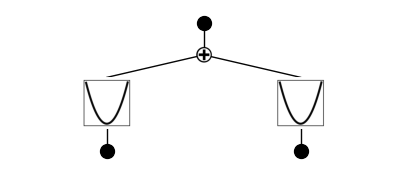

In [2]:
from xkan.viz import plot
plot(model, train['x']);

In [3]:
from xkan.symbolic import auto_symbolic
auto_symbolic(model, train['x'])

fixing (0,0,0) with x^2, r2=1.000000238418579, c=2


fixing (0,1,0) with x^2, r2=1.0000003576278687, c=2


{(0, 0, 0): ('x^2', np.float64(1.000000238418579), np.int64(2)),
 (0, 1, 0): ('x^2', np.float64(1.0000003576278687), np.int64(2))}

In [4]:
from xkan.symbolic import symbolic_formula
from xkan.utils import ex_round
ex_round(symbolic_formula(model)[0][0], 3)

7.11323896901055*x_1**2 + 7.11250581517067*x_2**2 - 15.003